<a href="https://colab.research.google.com/github/eyadshawky207-dev/IR-project/blob/main/linkldn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving LinkedIn_Data_Analyst_Jobs_Unstructured.csv to LinkedIn_Data_Analyst_Jobs_Unstructured.csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("LinkedIn_Data_Analyst_Jobs_Unstructured.csv")
print(df.head(3))
print(df.tail(2))

    doc_id           scraped_at                               title_raw  \
0  LI-0001  20/10/2026 11:10 PM  junior data analyst - 6 month contract   
1  LI-0002  24/10/2026 07:45 AM               Lead Data Analyst - Cairo   
2  LI-0003  2026-10-22 01:05:00                            Data Analyst   

                                        top_card_raw  \
0  Qanater Pharma  Egypt  ·  12 hours ago  ·  Ove...   
1  Nuvora Consulting  Giza, Al Jizah, Egypt  ·  R...   
2  Tamarind Insurance  Dubai, United Arab Emirate...   

                                    job_criteria_raw  \
0  Seniority level\nMid-Senior level\nEmployment ...   
1  Seniority level\nInternship\nEmployment type\n...   
2  Seniority level\nMid-Senior level\nEmployment ...   

                                     description_raw  
0  About the job\nAt Qanater Pharma, data is at t...  
1  About the job\nJoin Nuvora Consulting and help...  
2  <p><strong>About the job</strong></p><p>Tamari...  
      doc_id           scrape

In [ ]:
print(df.shape)
print(df.columns)
df.info()
print(df.describe(include="object"))
print(df.isnull().sum())

(122, 6)
Index(['doc_id', 'scraped_at', 'title_raw', 'top_card_raw', 'job_criteria_raw',
       'description_raw'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   doc_id            122 non-null    object
 1   scraped_at        118 non-null    object
 2   title_raw         122 non-null    object
 3   top_card_raw      122 non-null    object
 4   job_criteria_raw  99 non-null     object
 5   description_raw   122 non-null    object
dtypes: object(6)
memory usage: 5.8+ KB
         doc_id    scraped_at           title_raw  \
count       122           118                 122   
unique      122            98                  83   
top     LI-0001  Oct 21, 2026  Data Analyst (m/f)   
freq          1             6                   5   

                                             top_card_raw  \
count                  

In [ ]:
df = df.drop_duplicates(subset=["title_raw", "description_raw"])
print(df.shape)

(118, 6)


In [ ]:
df["title"] = (df["title_raw"].str.lower()
               .str.replace(r"[^a-z0-9 ]", " ", regex=True)
               .str.replace(r"\s+", " ", regex=True)
               .str.strip())

/tmp/ipykernel_1210/4185650476.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["title"] = (df["title_raw"].str.lower()


In [ ]:
first_line = df["top_card_raw"].str.split("\n").str[0]
loc_part = first_line.str.split("·").str[0].str.strip().str.split(r"\s{2,}")

df["company"] = loc_part.str[0]
df["location"] = loc_part.str[1]
df["country"] = (df["location"].str.split(",").str[-1].str.strip()
                 .replace({"Giza": "Egypt"}))
df["work_mode"] = df["top_card_raw"].str.extract(r"(Remote|Hybrid|On-site)")
df["applicants"] = pd.to_numeric(first_line.str.extract(r"(\d+)\s+applicants")[0])

/tmp/ipykernel_1210/173597746.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["company"] = loc_part.str[0]
/tmp/ipykernel_1210/173597746.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["location"] = loc_part.str[1]
/tmp/ipykernel_1210/173597746.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/inde

In [ ]:
df["seniority"] = df["job_criteria_raw"].str.extract(r"Seniority level\s+(.+?)\s+Employment type")
df["employment_type"] = df["job_criteria_raw"].str.extract(r"Employment type\s+(.+?)\s+Job function")
df["industry"] = df["job_criteria_raw"].str.extract(r"Industries\s+(.+)$")

df[["seniority", "employment_type", "industry"]] = df[["seniority", "employment_type", "industry"]].fillna("Not listed")

/tmp/ipykernel_1210/3807426141.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["seniority"] = df["job_criteria_raw"].str.extract(r"Seniority level\s+(.+?)\s+Employment type")
/tmp/ipykernel_1210/3807426141.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["employment_type"] = df["job_criteria_raw"].str.extract(r"Employment type\s+(.+?)\s+Job function")
/tmp/ipykernel_1210/3807426141.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[r

In [ ]:
df["scraped_at"] = pd.to_datetime(df["scraped_at"], format="mixed", dayfirst=True, utc=True)
df = df.dropna(subset=["scraped_at"])
df["scraped_date"] = df["scraped_at"].dt.date
df["desc_length"] = df["description_raw"].str.len()
print(df.shape)                    # (114, 17)

(114, 17)


/tmp/ipykernel_1210/3214285752.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["scraped_date"] = df["scraped_at"].dt.date
/tmp/ipykernel_1210/3214285752.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["desc_length"] = df["description_raw"].str.len()


In [ ]:
clean = df[["doc_id", "title", "company", "country", "work_mode", "employment_type",
            "seniority", "industry", "applicants", "scraped_date", "desc_length"]]
clean.head()

,doc_id,title,company,country,work_mode,employment_type,seniority,industry,applicants,scraped_date,desc_length
0,LI-0001,junior data analyst 6 month contract,Qanater Pharma,Egypt,Remote,Contract,Mid-Senior level,Pharmaceutical Manufacturing,200.0,2026-10-20,875
1,LI-0002,lead data analyst cairo,Nuvora Consulting,Egypt,On-site,Full-time,Internship,Business Consulting and Services,NaN,2026-10-24,873
2,LI-0003,data analyst,Tamarind Insurance,United Arab Emirates,Remote,Full-time,Mid-Senior level,Insurance,73.0,2026-10-22,1348
3,LI-0004,marketing data analyst immediate joiner,Corniche Bank,Saudi Arabia,Remote,Internship,Mid-Senior level,Banking,25.0,2026-10-21,977
4,LI-0005,risk data analyst hybrid,Nilewave Payments,Egypt,Hybrid,Internship,Associate,Financial Services,73.0,2026-10-24,574


In [ ]:
clean["work_mode"]
clean[["company", "country"]]

,company,country
0,Qanater Pharma,Egypt
1,Nuvora Consulting,Egypt
2,Tamarind Insurance,United Arab Emirates
3,Corniche Bank,Saudi Arabia
4,Nilewave Payments,Egypt
...,...,...
117,Najd Retail Holdings,Egypt
118,Lotus Bay Hotels,EMEA
119,Confidential,Egypt
120,Nilewave Payments,Egypt


In [ ]:
clean.loc[0:2]
clean.iloc[0:2]

,doc_id,title,company,country,work_mode,employment_type,seniority,industry,applicants,scraped_date,desc_length
0,LI-0001,junior data analyst 6 month contract,Qanater Pharma,Egypt,Remote,Contract,Mid-Senior level,Pharmaceutical Manufacturing,200.0,2026-10-20,875
1,LI-0002,lead data analyst cairo,Nuvora Consulting,Egypt,On-site,Full-time,Internship,Business Consulting and Services,NaN,2026-10-24,873


In [ ]:
clean[clean["applicants"] > 100]
egypt_remote = clean[(clean["country"] == "Egypt") & (clean["work_mode"] == "Remote")]
print(len(egypt_remote))

43


In [ ]:
clean["work_mode"].value_counts()

,count
work_mode,
Remote,57
On-site,32
Hybrid,25


In [ ]:
clean.sort_values(by="applicants", ascending=False).head(5)
clean.sort_values(by=["country", "applicants"], ascending=[True, False])

,doc_id,title,company,country,work_mode,employment_type,seniority,industry,applicants,scraped_date,desc_length
91,LI-0092,data analyst 6 month contract,Aswan Grid Energy,EMEA,Remote,Full-time,Mid-Senior level,Utilities,200.0,2026-10-19,779
76,LI-0077,reporting analyst,Saqqara Analytics,EMEA,Remote,Full-time,Associate,IT Services and IT Consulting,73.0,2026-10-20,839
118,LI-0119,data analyst,Lotus Bay Hotels,EMEA,Remote,Contract,Internship,Hospitality,47.0,2026-10-20,1165
75,LI-0076,business intelligence analyst,Quarzo Labs,EMEA,Remote,Not listed,Not listed,Not listed,25.0,2026-10-22,1092
63,LI-0064,commercial analyst remote,Sahara Cloud Solutions,EMEA,Remote,Temporary,Entry level,Software Development,19.0,2026-10-18,939
...,...,...,...,...,...,...,...,...,...,...,...
2,LI-0003,data analyst,Tamarind Insurance,United Arab Emirates,Remote,Full-time,Mid-Senior level,Insurance,73.0,2026-10-22,1348
29,LI-0030,senior data analyst hybrid,Tahrir Media Labs,United Arab Emirates,Remote,Internship,Mid-Senior level,Online Audio and Video Media,73.0,2026-10-19,867
103,LI-0104,healthcare data analyst immediate joiner,Sahara Cloud Solutions,United Arab Emirates,Hybrid,Part-time,Mid-Senior level,Software Development,73.0,2026-10-22,789
27,LI-0028,hiring healthcare data analyst,Confidential,United Arab Emirates,Remote,Internship,Associate,Staffing and Recruiting,25.0,2026-10-22,1067


In [ ]:
print(clean["applicants"].sum())
print(clean["applicants"].mean())
print(clean["applicants"].min())
print(clean["applicants"].max())
print(clean["applicants"].count())

6334.0
63.97979797979798
8.0
200.0
99


In [ ]:
print(clean.groupby("country")["applicants"].mean())
print(clean.groupby("work_mode")["applicants"].agg(["count", "mean", "max", "min"]))

country
EMEA                    72.80000
Egypt                   61.74359
Saudi Arabia            48.87500
United Arab Emirates    95.37500
Name: applicants, dtype: float64
           count       mean    max  min
work_mode                              
Hybrid        23  65.695652  200.0  8.0
On-site       27  73.185185  200.0  8.0
Remote        49  58.102041  200.0  8.0


In [ ]:
count_df = clean.groupby("country")["doc_id"].count().reset_index(name="jobs")
avg_df = clean.groupby("country")["applicants"].mean().round(1).reset_index(name="avg_applicants")
merged = pd.merge(count_df, avg_df, on="country", how="inner")
merged

,country,jobs,avg_applicants
0,EMEA,6,72.8
1,Egypt,92,61.7
2,Saudi Arabia,8,48.9
3,United Arab Emirates,8,95.4


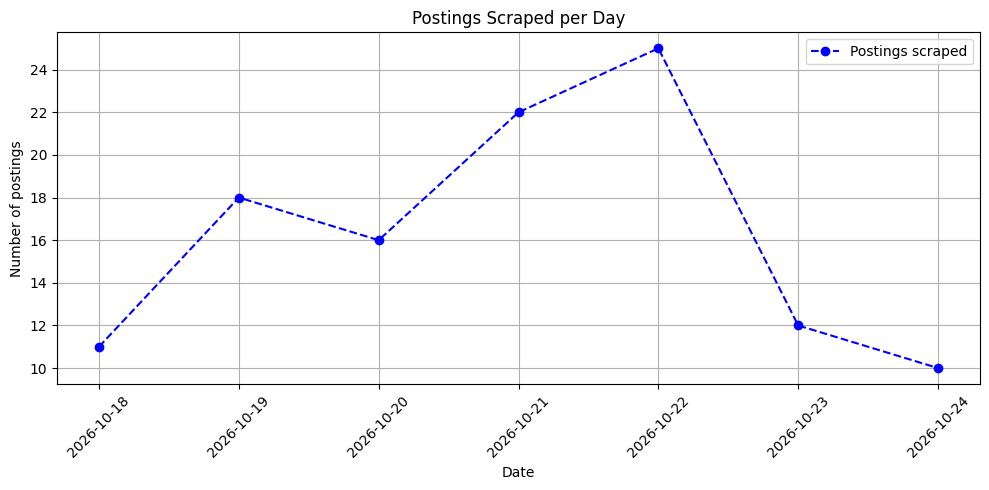

In [ ]:
daily = clean.groupby("scraped_date")["doc_id"].count()

plt.figure(figsize=(10, 5))
plt.plot(daily.index.astype(str), daily.values, color="blue",
         linestyle="--", marker="o", label="Postings scraped")
plt.title("Postings Scraped per Day")
plt.xlabel("Date")
plt.ylabel("Number of postings")
plt.xticks(rotation=45)
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

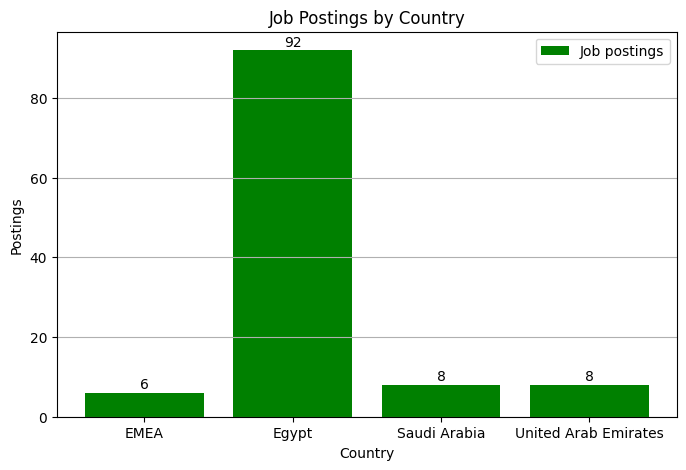

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(merged["country"], merged["jobs"], color="green", label="Job postings")
plt.title("Job Postings by Country")
plt.xlabel("Country")
plt.ylabel("Postings")
for i, v in enumerate(merged["jobs"]):
    plt.text(i, v + 1, str(v), ha="center")
plt.legend()
plt.grid(axis="y")
plt.show()

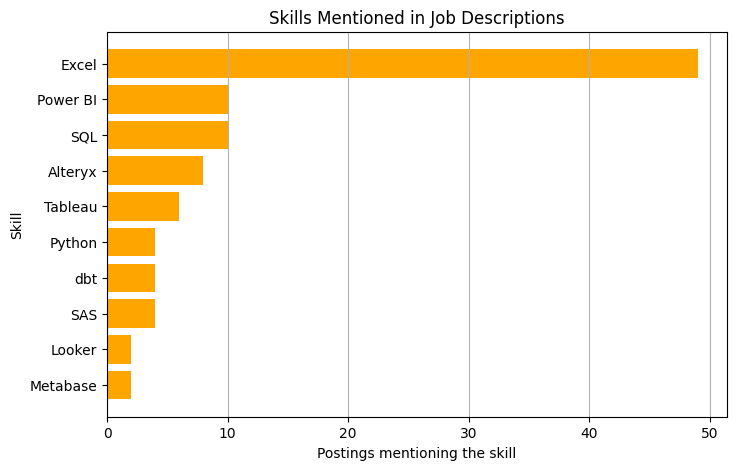

In [ ]:
skill_patterns = {"Excel": r"\bExcel\b", "SQL": r"\bSQL\b", "Power BI": r"Power BI",
                  "Alteryx": r"Alteryx", "Tableau": r"Tableau", "Python": r"\bPython\b",
                  "SAS": r"\bSAS\b", "dbt": r"\bdbt\b", "Looker": r"Looker", "Metabase": r"Metabase"}

skill_counts = pd.Series({k: df["description_raw"].str.contains(v, case=False, regex=True).sum()
                          for k, v in skill_patterns.items()}).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(skill_counts.index, skill_counts.values, color="orange")
plt.title("Skills Mentioned in Job Descriptions")
plt.xlabel("Postings mentioning the skill")
plt.ylabel("Skill")
plt.grid(axis="x")
plt.show()

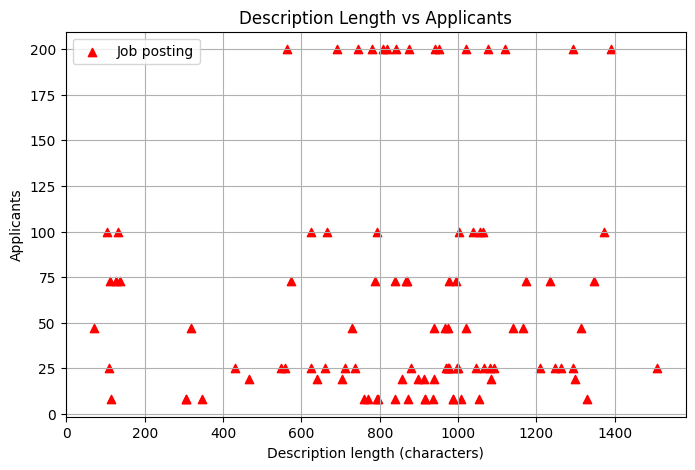

In [ ]:
sc = clean.dropna(subset=["applicants"])

plt.figure(figsize=(8, 5))
plt.scatter(sc["desc_length"], sc["applicants"], color="red", marker="^", label="Job posting")
plt.title("Description Length vs Applicants")
plt.xlabel("Description length (characters)")
plt.ylabel("Applicants")
plt.grid()
plt.legend()
plt.show()